# Chapter 07. 그래프로 데이터의 이야기를 보여주기

## 제출 정보
- 이름: 서지민
- GitHub ID: `jasminmuze`
- 작성일: 2026-10-27
- 최종 Notebook URL: https://github.com/jasminmuze/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

이번 분석은 Chapter 05에서 만든 `data/processed` 파일을 사용합니다. Chapter 05의 실습용 가상 쇼핑몰 데이터이며, 실제 기업이나 현재 시장을 대표하는 자료로 해석하지 않습니다. 금액은 데이터의 숫자 단위를 원으로 가정해 표시했으며, 원본 컬럼에는 통화 정보가 따로 없습니다.

이번 장에서는 그래프를 많이 만드는 대신, 질문에 맞는 그래프를 선택하고 원본 집계값과 그래프가 일치하는지 확인합니다.


## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 완료 주문 금액은 상품 카테고리별로 어떻게 다른가? | 정렬한 가로 막대그래프 | 범주 간 크기를 비교하기 쉽고, 0부터 시작하는 축으로 차이를 과장하지 않습니다. |
| 날짜가 확인되는 기간에 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | 월의 순서와 시간 흐름을 보여줍니다. 집계 행이 없는 달은 0으로 채우지 않고 선을 끊습니다. |
| 상품 목록 가격은 어떤 분포이며 극단값 후보가 있는가? | 히스토그램 | 가격이 몰린 구간과 긴 꼬리를 볼 수 있습니다. 최대값 때문에 로그 눈금을 사용하되 전체 범위를 표시합니다. |

금액 관련 그래프는 `order_status == completed`인 주문의 `line_total`만 사용합니다. 주문 상세 한 행은 상품 한 항목이므로, 월별 주문 수는 `order_id`의 고유 개수로 계산합니다.


In [1]:
from pathlib import Path
import math
import html
import numpy as np
import pandas as pd
from IPython.display import SVG, display

CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("data/processed 폴더가 없습니다. 저장소 루트에서 Notebook을 실행하세요.")

DATA_DIR = PROJECT_ROOT / "data" / "processed"
print("프로젝트 루트:", PROJECT_ROOT)
print("사용 데이터 폴더:", DATA_DIR)


프로젝트 루트: C:\Users\82102\.codex\.chatgpt-projects\g-p-6aa967e8f08481c2b96167c2c5768776\.chapter07-build
사용 데이터 폴더: C:\Users\82102\.codex\.chatgpt-projects\g-p-6aa967e8f08481c2b96167c2c5768776\.chapter07-build\data\processed


In [2]:
required_files = [
    DATA_DIR / "products_clean.csv",
    DATA_DIR / "orders_clean.csv",
    DATA_DIR / "order_items_clean.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError("필요한 Chapter 05 전처리 파일이 없습니다: " + ", ".join(map(str, missing_files)))

products = pd.read_csv(DATA_DIR / "products_clean.csv")
orders = pd.read_csv(DATA_DIR / "orders_clean.csv")
order_items = pd.read_csv(DATA_DIR / "order_items_clean.csv")

data_shapes = pd.DataFrame([
    {"자료": "products_clean", "행": len(products), "열": len(products.columns)},
    {"자료": "orders_clean", "행": len(orders), "열": len(orders.columns)},
    {"자료": "order_items_clean", "행": len(order_items), "열": len(order_items.columns)},
])
display(data_shapes)


자료,행,열
products_clean,96,4
orders_clean,300,7
order_items_clean,752,6


### 자료 범위와 개인정보

주문 상세 금액은 `line_total = quantity × unit_price`로 정의합니다. 분석 금액은 완료 주문에 한정하며 취소·환불 상태의 상세 행은 포함하지 않습니다. 이 Notebook은 고객 이름·고객 번호를 표시하지 않고 집계표와 가격 분포만 보여줍니다.

먼저 Chapter 05에서 저장한 `line_total`이 수량과 단가의 곱과 맞는지 확인하고, 처리 기준을 고정합니다.


In [3]:
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
line_total_matches = np.allclose(
    order_items["line_total"],
    order_items["quantity"] * order_items["unit_price"],
    equal_nan=True,
)
assert line_total_matches, "line_total이 quantity × unit_price와 일치하지 않습니다."

completed_orders = orders.loc[orders["order_status"].eq("completed")].copy()
completed_items = order_items.merge(
    orders[["order_id", "order_status", "order_date"]],
    on="order_id",
    how="inner",
    validate="many_to_one",
)
completed_items = completed_items.loc[completed_items["order_status"].eq("completed")].copy()

completed_total = float(completed_items["line_total"].sum())
invalid_date_items = completed_items.loc[completed_items["order_date"].isna()]
print("전체 주문 수:", orders["order_id"].nunique())
print("완료 주문 수:", completed_orders["order_id"].nunique())
print("완료 주문 상세 행 수:", len(completed_items))
print("완료 주문 금액 합계:", f"{completed_total:,.0f}원 (원 단위 가정)")
print("날짜를 확인할 수 없는 완료 주문 상세 행:", len(invalid_date_items))
print("날짜 미확인 행 금액:", f"{invalid_date_items['line_total'].sum():,.0f}원 (원 단위 가정)")


전체 주문 수: 300
완료 주문 수: 180
완료 주문 상세 행 수: 446
완료 주문 금액 합계: 141,340,000원 (원 단위 가정)
날짜를 확인할 수 없는 완료 주문 상세 행: 6
날짜 미확인 행 금액: 1,903,000원 (원 단위 가정)


## 2. 대표 그래프 1 — 카테고리별 완료 주문 금액

### 원본 집계값

완료 상태의 주문 상세를 상품 목록에 연결해 카테고리별 `line_total` 합계와 금액 비중을 계산합니다. 상품 목록에 연결되지 않은 행은 임의로 지우지 않고 `미매칭 상품`으로 둡니다.


In [4]:
completed_category_items = completed_items.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)
completed_category_items["category"] = completed_category_items["category"].fillna("미매칭 상품")
category_summary = (
    completed_category_items.groupby("category", as_index=False, dropna=False)
    .agg(
        item_rows=("order_item_id", "size"),
        total_quantity=("quantity", "sum"),
        completed_amount=("line_total", "sum"),
    )
    .sort_values("completed_amount", ascending=False)
    .reset_index(drop=True)
)
category_summary["amount_share_pct"] = (
    category_summary["completed_amount"] / completed_total * 100
).round(2)
display(category_summary)


category,item_rows,total_quantity,completed_amount,amount_share_pct
패션,76,290.0,32940000.0,23.31
식품,79,226.0,25035000.0,17.71
전자기기,58,176.0,21485000.0,15.20
도서,55,174.0,17663000.0,12.50
뷰티,61,168.0,17103000.0,12.10
스포츠,53,165.0,13237000.0,9.37
생활용품,37,108.0,7001000.0,4.95
미매칭 상품,16,34.0,4015000.0,2.84
생활 용품,5,17.0,2108000.0,1.49
뷰 티,5,12.0,648000.0,0.46


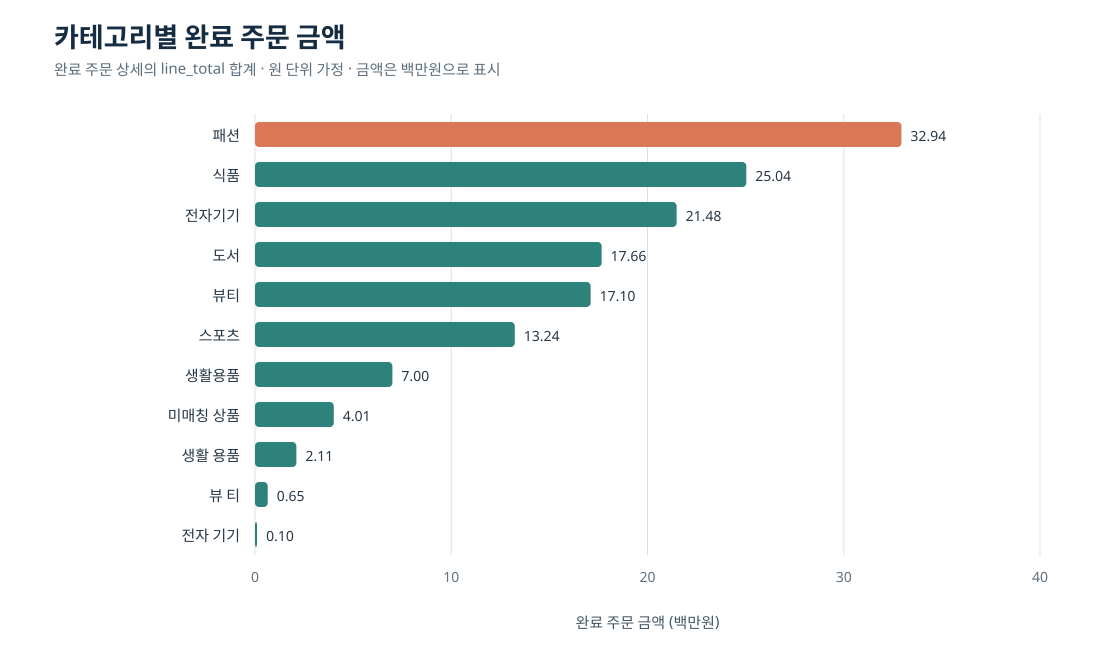

In [5]:
def _esc(value):
    return html.escape(str(value), quote=True)

def _svg_text(x, y, value, size=15, color="#273746", anchor="start", weight="400"):
    return f'<text x="{x:.1f}" y="{y:.1f}" font-family="sans-serif" font-size="{size}" font-weight="{weight}" fill="{color}" text-anchor="{anchor}">{_esc(value)}</text>'

def draw_category_bar(data):
    width, height = 1120, 650
    left, right, top, row_h, max_value = 255, 1040, 122, 40, 40.0
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<rect width="100%" height="100%" fill="white"/>']
    svg += [_svg_text(54, 47, "카테고리별 완료 주문 금액", 27, "#142D43", weight="700"),
            _svg_text(54, 75, "완료 주문 상세의 line_total 합계 · 원 단위 가정 · 금액은 백만원으로 표시", 15, "#5C6E7C")]
    for tick in range(0, 41, 10):
        x = left + tick / max_value * (right-left)
        svg += [f'<line x1="{x:.1f}" y1="{top-8}" x2="{x:.1f}" y2="{top+row_h*len(data)-7}" stroke="#D9E1E7"/>',
                _svg_text(x, top+row_h*len(data)+20, str(tick), 14, "#60717E", "middle")]
    for i, row in enumerate(data.itertuples(index=False)):
        y = top + i*row_h
        amount_m = float(row.completed_amount)/1_000_000
        bar_w = amount_m/max_value*(right-left)
        color = "#D97757" if i == 0 else "#2D827C"
        svg += [_svg_text(left-15, y+19, row.category, 15, "#273746", "end"),
                f'<rect x="{left}" y="{y}" width="{bar_w:.2f}" height="25" rx="4" fill="{color}"/>',
                _svg_text(left+bar_w+9, y+19, f"{amount_m:,.2f}", 14)]
    svg += [_svg_text((left+right)/2, height-22, "완료 주문 금액 (백만원)", 15, "#435563", "middle"), "</svg>"]
    return "\n".join(svg)

category_svg = draw_category_bar(category_summary)
display(SVG(category_svg))


### 결과 관찰

- 완료 주문 금액 합계는 **141,340,000원**입니다.
- 패션 카테고리가 **32,940,000원(23.31%)**으로 가장 큽니다. 다음은 식품 **25,035,000원(17.71%)**입니다.
- 가장 작은 범주인 기타 문구는 **105,000원(0.07%)**입니다.
- `미매칭 상품` 16개 주문 상세 행의 금액은 **4,015,000원(2.84%)**입니다.

### 나의 해석과 판단

현재 표본에서는 패션 상품의 완료 주문 금액 합계가 가장 큽니다. 그러나 금액 합계만으로 고객 선호를 단정할 수 없습니다. 판매 수량, 상품 단가, 등록 상품 수의 차이가 함께 반영된 값입니다. `생활용품`과 `생활 용품`, `뷰티`와 `뷰 티`처럼 정리되지 않은 표기는 원본 처리 기준을 넘어 임의 통합하지 않고 별도 범주로 남겼습니다.

### 업무·분석적 의미

운영 담당자는 패션 카테고리의 재고·가격 구성과 미매칭 상품의 등록 정보를 우선 확인할 수 있습니다. 다음 분석에서는 카테고리별 판매 수량과 주문당 금액을 함께 비교하는 편이 좋습니다.

### 한계와 추가 확인 사항

가상 실습 데이터의 완료 주문 180건만 다룹니다. 카테고리별 등록 상품 수가 다르고 일부 상품이 카테고리와 연결되지 않아, 상품 한 개당 성과나 고객 선호를 보여주는 그래프는 아닙니다. 미매칭 상품과 범주 표기 차이를 확인한 뒤 재집계할 필요가 있습니다.


## 3. 대표 그래프 2 — 월별 완료 주문 금액

### 원본 집계값

완료 주문 상세에서 날짜가 유효한 행만 월별로 합산합니다. 월별 주문 수는 서로 다른 `order_id`의 개수이며, 날짜가 없는 주문 상세는 월에 억지로 넣지 않습니다.


In [6]:
dated_completed_items = completed_items.dropna(subset=["order_date"]).copy()
dated_completed_items["order_month"] = dated_completed_items["order_date"].dt.to_period("M").astype(str)
monthly_summary = (
    dated_completed_items.groupby("order_month", as_index=False)
    .agg(
        completed_amount=("line_total", "sum"),
        completed_order_count=("order_id", "nunique"),
    )
    .sort_values("order_month")
    .set_index("order_month")
)
monthly_summary["average_order_amount"] = (
    monthly_summary["completed_amount"] / monthly_summary["completed_order_count"]
).round(0)
full_months = pd.period_range(monthly_summary.index.min(), monthly_summary.index.max(), freq="M").astype(str).tolist()
monthly_plot = monthly_summary.reindex(full_months)
missing_months = [month for month in full_months if month not in monthly_summary.index]
display(monthly_summary.reset_index())


order_month,completed_amount,completed_order_count,average_order_amount
2025-07,9561000.0,11,869182.0
2025-08,9362000.0,17,550706.0
2025-09,5299000.0,4,1324750.0
2025-10,12629000.0,17,742882.0
2025-11,9583000.0,16,598938.0
2025-12,8581000.0,12,715083.0
2026-01,8135000.0,9,903889.0
2026-02,7689000.0,12,640750.0
2026-03,7247000.0,13,557462.0
2026-04,11459000.0,14,818500.0


In [7]:
print("월별 집계 행이 없는 달:", ", ".join(missing_months) if missing_months else "없음")
print("날짜 미확인 완료 주문 상세 행:", len(invalid_date_items))
print("날짜 미확인 상세 금액:", f"{invalid_date_items['line_total'].sum():,.0f}원 (원 단위 가정)")


월별 집계 행이 없는 달: 2026-09, 2026-10, 2026-11, 2026-12
날짜 미확인 완료 주문 상세 행: 6
날짜 미확인 상세 금액: 1,903,000원 (원 단위 가정)


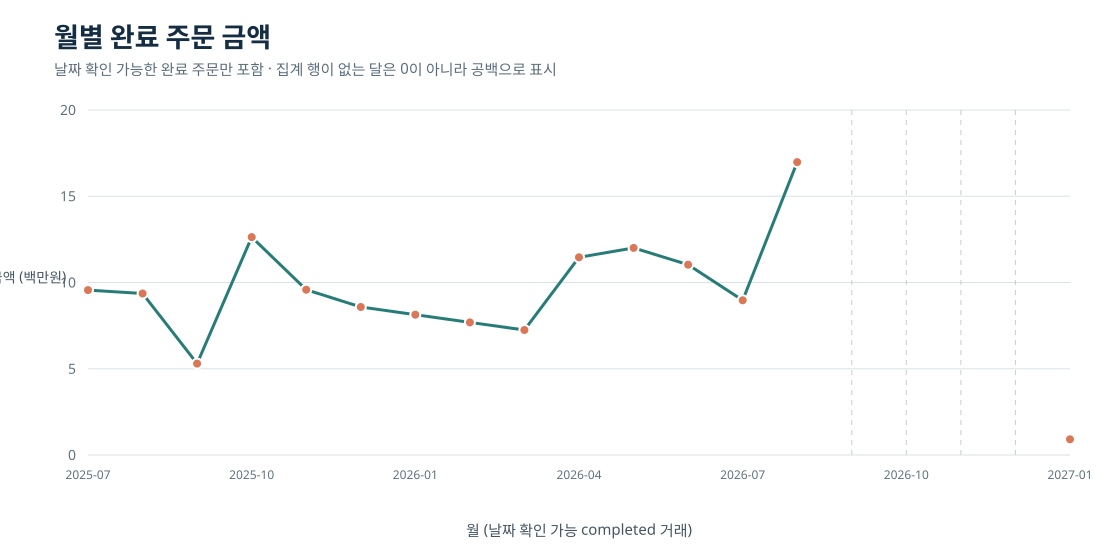

In [8]:
def draw_month_line(data):
    width, height = 1120, 560
    left, right, top, bottom, y_max = 88, 1070, 110, 455, 20.0
    months = list(data.index)
    x_pos = {month: left + i/max(1, len(months)-1)*(right-left) for i, month in enumerate(months)}
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<rect width="100%" height="100%" fill="white"/>']
    svg += [_svg_text(54, 47, "월별 완료 주문 금액", 27, "#142D43", weight="700"),
            _svg_text(54, 75, "날짜 확인 가능한 완료 주문만 포함 · 집계 행이 없는 달은 0이 아니라 공백으로 표시", 15, "#5C6E7C")]
    for tick in range(0, 21, 5):
        y = bottom - tick/y_max*(bottom-top)
        svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{right}" y2="{y:.1f}" stroke="#D9E1E7"/>',
                _svg_text(left-12, y+5, str(tick), 14, "#60717E", "end")]
    points = []
    for month in months:
        value = data.loc[month, "completed_amount"]
        points.append(None if pd.isna(value) else (x_pos[month], bottom-float(value)/1_000_000/y_max*(bottom-top)))
    segments, current = [], []
    for point in points:
        if point is None:
            if current:
                segments.append(current)
                current = []
        else:
            current.append(point)
    if current:
        segments.append(current)
    for segment in segments:
        path = " ".join(("M" if i == 0 else "L") + f" {x:.1f} {y:.1f}" for i, (x, y) in enumerate(segment))
        svg.append(f'<path d="{path}" fill="none" stroke="#287C78" stroke-width="3" stroke-linecap="round" stroke-linejoin="round"/>')
    for i, (month, point) in enumerate(zip(months, points)):
        x = x_pos[month]
        if point is None:
            svg.append(f'<line x1="{x:.1f}" y1="{top}" x2="{x:.1f}" y2="{bottom}" stroke="#C8CDD2" stroke-dasharray="5,5"/>')
        else:
            px, py = point
            svg.append(f'<circle cx="{px:.1f}" cy="{py:.1f}" r="5" fill="#D97757" stroke="white" stroke-width="2"/>')
        if i % 3 == 0 or i == len(months)-1:
            svg.append(_svg_text(x, bottom+24, month, 12, "#60717E", "middle"))
    svg += [_svg_text((left+right)/2, height-24, "월 (날짜 확인 가능 completed 거래)", 15, "#435563", "middle"),
            _svg_text(28, (top+bottom)/2, "금액 (백만원)", 14, "#435563", "middle"), "</svg>"]
    return "\n".join(svg)

monthly_svg = draw_month_line(monthly_plot)
display(SVG(monthly_svg))


### 결과 관찰

- 날짜가 있는 완료 주문 금액은 **139,437,000원**입니다. 날짜를 확인할 수 없는 상세 행 6개의 **1,903,000원**은 월별 그래프에서 제외해 별도로 표시했습니다.
- 날짜가 있는 월 중 2026년 8월이 **16,980,000원, 15건**으로 가장 큽니다. 2027년 1월은 **909,000원, 1건**입니다.
- 2026년 9~12월에는 날짜가 있는 완료 주문 집계 행이 없습니다. 그래프는 해당 구간을 0으로 채우거나 앞뒤 점을 연결하지 않았습니다.

### 나의 해석과 판단

관찰 기간에 월별 금액은 오르내리며, 2026년 8월에 가장 큰 금액이 나타났습니다. 2027년 1월은 주문 1건뿐이므로 앞선 달과 금액을 직접 비교해 추세라고 단정하기 어렵습니다. 그래프는 월별 관찰값을 보여줄 뿐 상승·하락의 이유를 설명하지 않습니다.

### 업무·분석적 의미

추가 분석에서는 월별 총액과 주문 수, 주문당 평균 금액을 나란히 확인할 수 있습니다. 특히 날짜 미확인 6개 상세 행의 원본 날짜를 점검하고, 2026년 9~12월에 거래가 없었는지 데이터 수집 공백인지 확인해야 합니다.

### 한계와 추가 확인 사항

기간은 2025년 7월부터 2027년 1월까지로 짧고, 일부 주문 상세의 날짜가 비어 있습니다. 월별 집계 행이 없다는 사실만으로 실제 매출이 0이었다고 판단할 수 없습니다. 계절성이나 변동 원인을 주장하려면 더 긴 기간과 판촉·영업일 등 추가 자료가 필요합니다.


## 4. 대표 그래프 3 — 상품 목록 가격 분포

### 원본 집계값

거래별 단가가 아니라 Chapter 05에서 정리된 상품 목록의 `price` 96개를 사용합니다. 최대값이 다른 가격과 큰 차이가 있어 로그 눈금의 20개 구간을 사용하고, 가격 범위를 자르지 않습니다.


In [9]:
prices = products["price"].dropna().astype(float)
q1 = float(prices.quantile(0.25))
median_price = float(prices.median())
q3 = float(prices.quantile(0.75))
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outlier_candidate_count = int((prices > upper_fence).sum())
price_summary = pd.DataFrame([{
    "상품 수": len(prices),
    "최솟값(원 가정)": prices.min(),
    "제1사분위수": q1,
    "중앙값": median_price,
    "제3사분위수": q3,
    "평균": prices.mean(),
    "최댓값": prices.max(),
    "IQR 상한": upper_fence,
    "상한 초과 후보 수": outlier_candidate_count,
}])
display(price_summary.round(1))


상품 수,최솟값(원 가정),제1사분위수,중앙값,제3사분위수,평균,최댓값,IQR 상한,상한 초과 후보 수
96,5000.0,52750.0,94500.0,153250.0,204895.8,9999999.0,304000.0,1


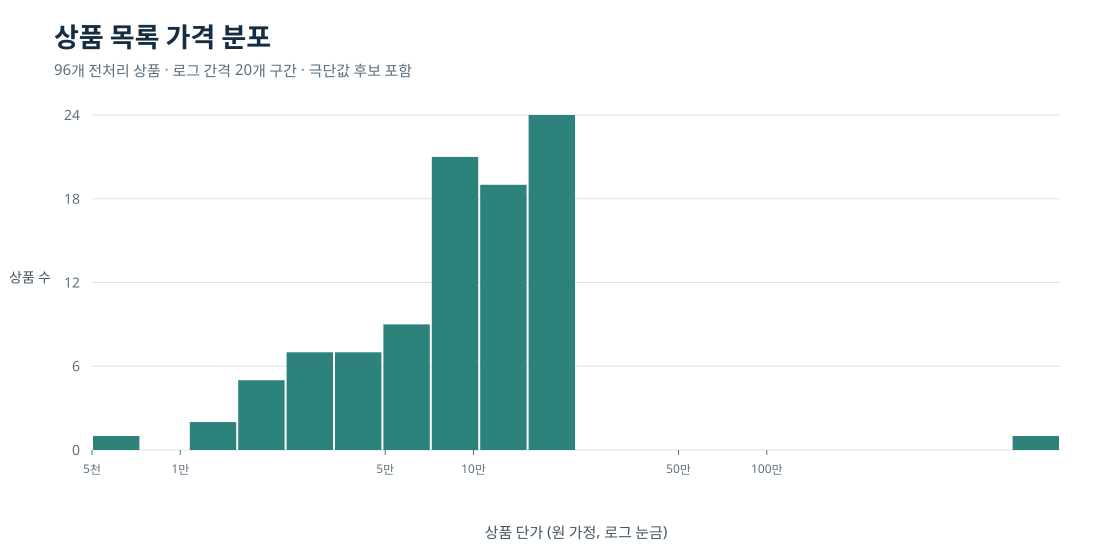

In [10]:
def draw_price_hist(prices, bins=20):
    values = prices.dropna().to_numpy(dtype=float)
    edges = np.geomspace(float(values.min()), float(values.max()), bins+1)
    counts, edges = np.histogram(values, bins=edges)
    width, height = 1120, 560
    left, right, top, bottom = 92, 1060, 115, 450
    log_min, log_max = math.log10(float(edges[0])), math.log10(float(edges[-1]))
    y_max = max(4, int(math.ceil(float(counts.max())/4)*4))
    svg = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<rect width="100%" height="100%" fill="white"/>']
    svg += [_svg_text(54, 47, "상품 목록 가격 분포", 27, "#142D43", weight="700"),
            _svg_text(54, 75, f"{len(values)}개 전처리 상품 · 로그 간격 {bins}개 구간 · 극단값 후보 포함", 15, "#5C6E7C")]
    for tick in range(0, y_max+1, max(1, y_max//4)):
        y = bottom - tick/y_max*(bottom-top)
        svg += [f'<line x1="{left}" y1="{y:.1f}" x2="{right}" y2="{y:.1f}" stroke="#D9E1E7"/>',
                _svg_text(left-12, y+5, str(tick), 14, "#60717E", "end")]
    for i, count in enumerate(counts):
        x0 = left + (math.log10(float(edges[i]))-log_min)/(log_max-log_min)*(right-left)
        x1 = left + (math.log10(float(edges[i+1]))-log_min)/(log_max-log_min)*(right-left)
        bar_h = float(count)/y_max*(bottom-top)
        svg.append(f'<rect x="{x0+1:.2f}" y="{bottom-bar_h:.2f}" width="{max(1,x1-x0-2):.2f}" height="{bar_h:.2f}" fill="#2D827C"/>')
    tick_values = [5_000, 10_000, 50_000, 100_000, 500_000, 1_000_000, 10_000_000]
    tick_labels = ["5천", "1만", "5만", "10만", "50만", "100만", "1000만"]
    for value, label in zip(tick_values, tick_labels):
        x = left + (math.log10(value)-log_min)/(log_max-log_min)*(right-left)
        if left <= x <= right:
            svg += [f'<line x1="{x:.1f}" y1="{bottom}" x2="{x:.1f}" y2="{bottom+5}" stroke="#60717E"/>',
                    _svg_text(x, bottom+23, label, 12, "#60717E", "middle")]
    svg += [_svg_text((left+right)/2, height-22, "상품 단가 (원 가정, 로그 눈금)", 15, "#435563", "middle"),
            _svg_text(30, (top+bottom)/2, "상품 수", 14, "#435563", "middle"), "</svg>"]
    return "\n".join(svg), counts

price_svg, price_bin_counts = draw_price_hist(prices, bins=20)
display(SVG(price_svg))


### 결과 관찰

- 상품 목록 96개의 가격 중앙값은 **94,500원**, 평균은 약 **204,896원**입니다.
- 가격 범위는 **5,000원~9,999,999원**입니다. IQR 방식의 상한은 **304,000원**이고, 이를 넘는 가격 후보는 1개입니다.
- 평균이 중앙값보다 큰 것은 매우 높은 가격 한 건의 영향을 받은 결과일 수 있습니다.

### 나의 해석과 판단

가격은 낮은 구간에 주로 분포하고 높은 가격 쪽으로 긴 꼬리가 있습니다. 9,999,999원은 이상값 후보지만, 그래프만으로 입력 오류라고 단정할 수는 없습니다. 원본 상품 정보나 수집 기록을 확인하기 전까지 제외하지 않습니다.

### 업무·분석적 의미

상품 등록 담당자는 해당 가격의 원본과 단위를 우선 확인할 수 있습니다. 가격대별 상품 구성을 설명할 때는 평균만 제시하지 않고 중앙값과 범위를 같이 제시하는 것이 안전합니다.

### 한계와 추가 확인 사항

이는 판매된 상품 가격의 분포가 아니라 전처리된 상품 목록의 가격 분포입니다. 실제 구매 빈도나 매출 기여도를 나타내지 않습니다. 통화 단위도 원본 CSV에 별도 컬럼이 없어 원으로 가정해 표현했습니다.


## 5. 그래프와 수치 교차 검증

범주별 합계와 월별 합계를 같은 완료 주문 상세 금액과 비교합니다. 월별 표는 날짜가 있는 행만 포함하므로 날짜 미확인 금액을 별도 합산해야 전체 금액과 맞습니다. 히스토그램의 구간별 개수 합은 상품 가격 관측 수와 같아야 합니다.


In [11]:
category_total = float(category_summary["completed_amount"].sum())
monthly_valid_total = float(monthly_summary["completed_amount"].sum())
unknown_date_total = float(invalid_date_items["line_total"].sum())
histogram_count = int(price_bin_counts.sum())

assert np.isclose(category_total, completed_total)
assert np.isclose(monthly_valid_total + unknown_date_total, completed_total)
assert histogram_count == len(prices)
assert np.isclose(category_summary.iloc[0]["completed_amount"], 32_940_000)
assert np.isclose(monthly_summary.loc["2026-08", "completed_amount"], 16_980_000)

validation = pd.DataFrame([
    {"검증 항목": "카테고리 합계 = 완료 주문 상세 전체", "집계값(원 가정)": category_total, "결과": "일치" if np.isclose(category_total, completed_total) else "불일치"},
    {"검증 항목": "날짜 유효 월별 합계 + 날짜 미확인 상세", "집계값(원 가정)": monthly_valid_total + unknown_date_total, "결과": "일치" if np.isclose(monthly_valid_total + unknown_date_total, completed_total) else "불일치"},
    {"검증 항목": "히스토그램 구간별 상품 수 합", "집계값(개)": histogram_count, "결과": "일치" if histogram_count == len(prices) else "불일치"},
])
display(validation)


검증 항목,집계값(원 가정),결과,집계값(개)
카테고리 합계 = 완료 주문 상세 전체,141340000.0,일치,NaN
날짜 유효 월별 합계 + 날짜 미확인 상세,141340000.0,일치,NaN
히스토그램 구간별 상품 수 합,NaN,일치,96.0


### 그래프 정확성 점검

- 막대그래프 축은 0부터 시작하고 금액 단위를 표시했습니다.
- 막대그래프는 완료 주문 상세의 집계표를 내림차순으로 그렸습니다.
- 선그래프는 월 순서로 정렬했습니다. 2026년 9~12월은 집계 행이 없어 0으로 대체하지 않고 구간을 끊었습니다.
- 가격 히스토그램은 5,000원부터 9,999,999원까지 전체 범위를 로그 눈금으로 표시했습니다. IQR 후보도 삭제하지 않았습니다.
- 범주별 합계는 완료 주문 상세 금액 합계와 일치했습니다. 월별 금액과 날짜 미확인 금액의 합도 전체 완료 주문 금액과 일치했습니다. 히스토그램 구간 수 합은 상품 수 96개와 일치했습니다.
- 고객 이름과 개별 고객 번호는 그래프나 출력에 포함하지 않았습니다.

## 6. Chapter 07 최종 판단

가장 중요한 그래프는 **카테고리별 완료 주문 금액 막대그래프**입니다. 완료 주문 총액 141,340,000원 중 패션 카테고리가 32,940,000원으로 가장 큰 금액을 보였다는 사실을 한눈에 비교할 수 있습니다. 이것은 관찰 결과이며 패션 선호의 원인이나 시장 전체의 특성을 증명하지 않습니다.

다음 분석에서는 카테고리별 등록 상품 수, 판매 수량, 단가를 함께 비교해 금액 차이가 어떤 요소와 함께 나타나는지 확인하겠습니다. 범주 표기 차이와 미매칭 상품도 원본 정의를 확인한 뒤 재분류하겠습니다.

## LLM 활용과 검증 기록

LLM은 질문 구성, 그래프 선택, 코드 초안과 해석 문장 정리에 활용했습니다. 수치와 해석은 Chapter 05의 실제 `processed` CSV를 다시 읽어 계산하고, `line_total` 산식과 카테고리·월별 합계를 검증했습니다. 그래프에는 검증된 집계 결과만 전달했습니다. 날짜가 없는 달을 0으로 채우지 않는 처리와 가격 이상값을 자동 삭제하지 않는 판단도 데이터 범위와 그래프 결과를 기준으로 확인했습니다.

### 자료 출처

- Chapter 05 전처리 데이터: [개인 GitHub 저장소의 `data/processed`](https://github.com/jasminmuze/llm-data-analysis-study/tree/main/data/processed)
- Chapter 07 시각화 실습 안내: [강의 공개 저장소](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/practice/chapter07/chapter07.md)
